# Módulo 13 · Análisis de datos con NumPy, pandas y matplotlib

**Curso:** Python desde cero · **Duración estimada:** 4 h

> **Nota:** este módulo usa paquetes externos. Ejecútelo en Jupyter (Anaconda) o Google Colab.

## Objetivos

Al terminar este módulo usted podrá:

- Hacer cálculos sobre columnas completas con NumPy.
- Crear, explorar, filtrar y resumir tablas con pandas.
- Leer y escribir CSV y Excel con pandas.
- Elaborar gráficos básicos con matplotlib.

## Cómo usar este cuaderno

1. Lea cada lección y ejecute los ejemplos con **Shift + Enter**.
2. Modifique los ejemplos: cambie valores y observe qué pasa. Así se aprende.
3. Resuelva los ejercicios en la celda indicada y ejecute la **celda de comprobación**.
4. Si se atasca, abra la **pista**. Las soluciones están en la carpeta `soluciones/`.
5. Termine con la **autoevaluación**.

## 1. Preparar el entorno

Este módulo usa paquetes externos y **no se ejecuta en el curso interactivo del navegador**: utilice **Jupyter (Anaconda)** o **Google Colab**, donde ya vienen instalados. Si faltara alguno: `%pip install numpy pandas matplotlib openpyxl`.

Por convención se importan con alias cortos: `np`, `pd` y `plt`.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
print("numpy", np.__version__)
print("pandas", pd.__version__)

numpy 2.5.3
pandas 3.0.5


## 2. NumPy: cálculos sobre muchos valores a la vez

Un **arreglo** (`np.array`) aplica una operación a **todos los elementos sin escribir bucles** (cálculo vectorizado). Es mucho más rápido que recorrer una lista.

In [ ]:
import numpy as np

dap_cm = np.array([32.5, 18.0, 45.2, 22.7, 27.1])
ab = np.pi / 4 * (dap_cm / 100) ** 2      # sin bucle
print(np.round(ab, 4))
print("AB total:", round(ab.sum(), 4), "m2")
print("DAP medio:", dap_cm.mean(), "| máximo:", dap_cm.max())
print(dap_cm[dap_cm > 25])                 # filtro

[0.083  0.0254 0.1605 0.0405 0.0577]
AB total: 0.367 m2
DAP medio: 29.1 | máximo: 45.2
[32.5 45.2 27.1]


## 3. pandas: la tabla (DataFrame)

Un **DataFrame** es una tabla con filas y columnas con nombre, como una hoja de Excel. Cada columna es una **Serie**.

| Instrucción | Qué muestra |
|---|---|
| `df.head()` | primeras 5 filas |
| `df.shape` | (filas, columnas) |
| `df.columns` | nombres de columnas |
| `df.dtypes` | tipo de cada columna |
| `df.describe()` | estadísticas de columnas numéricas |

*Datos ficticios de ejemplo.*

In [ ]:
import pandas as pd

df = pd.DataFrame({
    "codigo": ["A-01", "A-02", "A-03", "A-04", "A-05", "A-06"],
    "especie": ["Algarrobo", "Faique", "Algarrobo", "Hualtaco", "Faique", "Algarrobo"],
    "dap_cm": [32.5, 18.0, 45.2, 22.7, 20.4, 38.1],
    "altura_m": [9.0, 6.5, 11.0, 8.2, 7.0, 10.4],
})
print(df.shape)
print(df.head())
print(df.describe().round(2))

(6, 4)
  codigo    especie  dap_cm  altura_m
0   A-01  Algarrobo    32.5       9.0
1   A-02     Faique    18.0       6.5
2   A-03  Algarrobo    45.2      11.0
3   A-04   Hualtaco    22.7       8.2
4   A-05     Faique    20.4       7.0
       dap_cm  altura_m
count    6.00      6.00
mean    29.48      8.68
std     10.87      1.80
min     18.00      6.50
25%     20.98      7.30
50%     27.60      8.60
75%     36.70     10.05
max     45.20     11.00


## 4. Seleccionar, filtrar y crear columnas

- Una columna: `df["dap_cm"]`; varias: `df[["codigo", "dap_cm"]]`.
- Filtrar filas: `df[df["dap_cm"] > 30]`. Combinar condiciones con `&` (y) y `|` (o), cada una entre paréntesis.
- Crear una columna: `df["nueva"] = cálculo`, que se aplica a todas las filas.

In [ ]:
import numpy as np
import pandas as pd

df = pd.DataFrame({
    "codigo": ["A-01", "A-02", "A-03", "A-04", "A-05", "A-06"],
    "especie": ["Algarrobo", "Faique", "Algarrobo", "Hualtaco", "Faique", "Algarrobo"],
    "dap_cm": [32.5, 18.0, 45.2, 22.7, 20.4, 38.1],
    "altura_m": [9.0, 6.5, 11.0, 8.2, 7.0, 10.4],
})
df["ab_m2"] = np.pi / 4 * (df["dap_cm"] / 100) ** 2
df["vol_m3"] = df["ab_m2"] * df["altura_m"] * 0.5      # ff supuesto 0.5

grandes = df[(df["dap_cm"] > 30) & (df["especie"] == "Algarrobo")]
print(grandes[["codigo", "dap_cm", "vol_m3"]].round(4))

  codigo  dap_cm  vol_m3
0   A-01    32.5  0.3733
2   A-03    45.2  0.8825
5   A-06    38.1  0.5928


## 5. Agrupar y resumir

`groupby` agrupa filas por una columna y resume las demás (equivale a una **tabla dinámica** de Excel).

`agg` permite nombrar varias estadísticas a la vez.

In [ ]:
import numpy as np
import pandas as pd

df = pd.DataFrame({
    "especie": ["Algarrobo", "Faique", "Algarrobo", "Hualtaco", "Faique", "Algarrobo"],
    "dap_cm": [32.5, 18.0, 45.2, 22.7, 20.4, 38.1],
    "altura_m": [9.0, 6.5, 11.0, 8.2, 7.0, 10.4],
})
df["ab_m2"] = np.pi / 4 * (df["dap_cm"] / 100) ** 2

resumen = df.groupby("especie").agg(
    n_arboles=("dap_cm", "count"),
    dap_medio=("dap_cm", "mean"),
    ab_total=("ab_m2", "sum"),
).round(3)
print(resumen.sort_values("ab_total", ascending=False))

           n_arboles  dap_medio  ab_total
especie                                  
Algarrobo          3       38.6     0.357
Faique             2       19.2     0.058
Hualtaco           1       22.7     0.040


## 6. Leer y guardar CSV y Excel

- `pd.read_csv("archivo.csv")` y `pd.read_excel("archivo.xlsx", sheet_name="Hoja1")` leen archivos.
- `df.to_csv("salida.csv", index=False)` y `df.to_excel("salida.xlsx", index=False)` los guardan (Excel requiere el paquete `openpyxl`).
- Para un CSV con punto y coma y coma decimal (configuración regional de Perú): `pd.read_csv("archivo.csv", sep=";", decimal=",")`.

In [ ]:
import io
import pandas as pd

texto = """parcela;arboles;area_ha
P-01;45;0,5
P-02;38;0,5
P-03;52;0,4
"""
df = pd.read_csv(io.StringIO(texto), sep=";", decimal=",")
df["densidad_ha"] = df["arboles"] / df["area_ha"]
print(df)
# df.to_excel("densidad.xlsx", index=False)   # guardaría en Excel

  parcela  arboles  area_ha  densidad_ha
0    P-01       45      0.5         90.0
1    P-02       38      0.5         76.0
2    P-03       52      0.4        130.0


## 7. Gráficos con matplotlib

Pasos básicos: crear la figura, dibujar, rotular ejes y título, y mostrar (`plt.show()`). Siempre indique **unidades** en los ejes.

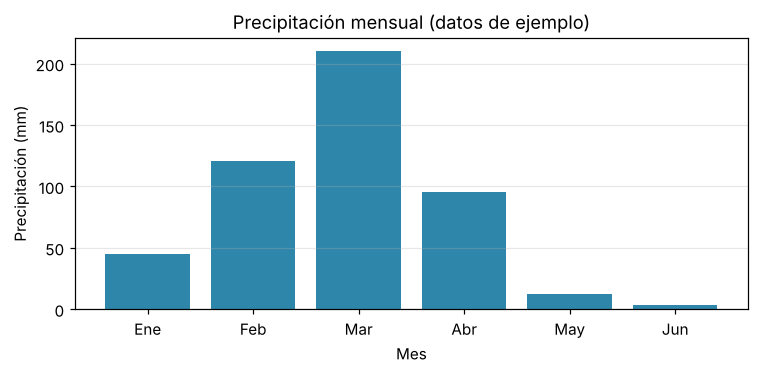

In [ ]:
import matplotlib.pyplot as plt

meses = ["Ene", "Feb", "Mar", "Abr", "May", "Jun"]
lluvia = [45.2, 120.8, 210.5, 95.3, 12.0, 3.4]   # datos ficticios

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(meses, lluvia, color="#2E86AB")
ax.set_xlabel("Mes")
ax.set_ylabel("Precipitación (mm)")
ax.set_title("Precipitación mensual (datos de ejemplo)")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

---
# Ejercicios

Escriba su solución en la celda de código de cada ejercicio, ejecútela y luego ejecute la **celda de comprobación** que está debajo. Si todo está bien verá `✔ ¡Correcto!`; si no, un mensaje le indicará qué revisar.

Niveles: ★☆☆ básico · ★★☆ intermedio · ★★★ reto.

### Ejercicio 1 · Área basal con NumPy  ★☆☆

Calcule en `ab_total` la suma del área basal (m²) de todos los árboles, sin bucles.

<details><summary><b>Ver pista</b></summary>

`(np.pi / 4 * (dap_cm / 100) ** 2).sum()`

</details>

In [ ]:
import numpy as np

dap_cm = np.array([20, 30, 40, 50])
ab_total = 0
print(round(ab_total, 4))

In [ ]:
# Comprobación del ejercicio (no modifique esta celda)
assert abs(ab_total - 0.4241150) < 1e-6, f"Se esperaba ≈ 0.4241; se obtuvo {ab_total}."
print("✔ ¡Correcto! Ejercicio resuelto.")

### Ejercicio 2 · Filtrar un DataFrame  ★☆☆

Guarde en `n_altos` cuántos árboles tienen altura mayor a 8 m.

<details><summary><b>Ver pista</b></summary>

`len(df[df["altura_m"] > 8])`

</details>

In [ ]:
import pandas as pd

df = pd.DataFrame({"altura_m": [9.0, 6.5, 11.0, 8.2, 7.0, 10.4]})
n_altos = 0
print(n_altos)

In [ ]:
# Comprobación del ejercicio (no modifique esta celda)
assert n_altos == 4, f"Son 4 árboles; se obtuvo {n_altos}."
print("✔ ¡Correcto! Ejercicio resuelto.")

### Ejercicio 3 · Promedio por especie  ★★☆

Guarde en `medias` una Serie con el DAP medio por especie usando `groupby`.

<details><summary><b>Ver pista</b></summary>

`df.groupby("especie")["dap_cm"].mean()`

</details>

In [ ]:
import pandas as pd

df = pd.DataFrame({
    "especie": ["Algarrobo", "Faique", "Algarrobo", "Faique"],
    "dap_cm": [30, 18, 40, 22],
})
medias = None
print(medias)

In [ ]:
# Comprobación del ejercicio (no modifique esta celda)
assert medias["Algarrobo"] == 35 and medias["Faique"] == 20, "Revise el agrupamiento."
print("✔ ¡Correcto! Ejercicio resuelto.")

### Ejercicio 4 · Columna calculada  ★★☆

Agregue la columna `densidad` (árboles / área) y guarde en `max_parcela` el nombre de la parcela con mayor densidad.

<details><summary><b>Ver pista</b></summary>

`df["densidad"] = df["arboles"] / df["area_ha"]`; luego `df.loc[df["densidad"].idxmax(), "parcela"]`.

</details>

In [ ]:
import pandas as pd

df = pd.DataFrame({
    "parcela": ["P-01", "P-02", "P-03"],
    "arboles": [45, 38, 52],
    "area_ha": [0.5, 0.25, 0.8],
})
max_parcela = ""
print(df)
print(max_parcela)

In [ ]:
# Comprobación del ejercicio (no modifique esta celda)
assert "densidad" in df.columns, "Falta la columna densidad."
assert list(df["densidad"]) == [90.0, 152.0, 65.0], "Revise el cálculo de densidad."
assert max_parcela == "P-02", f"Se esperaba 'P-02'; se obtuvo {max_parcela!r}."
print("✔ ¡Correcto! Ejercicio resuelto.")

---
# Autoevaluación

Responda mentalmente y luego despliegue la respuesta.

**1. ¿Qué ventaja tiene NumPy frente a una lista con bucle?**

   a) Ninguna
   b) Opera sobre todos los elementos a la vez y es más rápido
   c) Solo guarda textos
   d) No requiere importarse

<details><summary>Ver respuesta</summary>

**b)** Opera sobre todos los elementos a la vez y es más rápido. Las operaciones vectorizadas evitan bucles y son mucho más rápidas.

</details>

**2. ¿Cómo se filtran las filas con dap_cm mayor a 30?**

   a) df.dap_cm > 30
   b) df[df["dap_cm"] > 30]
   c) df.filter(30)
   d) df[30]

<details><summary>Ver respuesta</summary>

**b)** df[df["dap_cm"] > 30]. La condición se coloca dentro de df[...] para seleccionar filas.

</details>

**3. ¿A qué herramienta de Excel equivale groupby?**

   a) Buscarv
   b) Tabla dinámica
   c) Formato condicional
   d) Gráfico

<details><summary>Ver respuesta</summary>

**b)** Tabla dinámica. groupby agrupa y resume, como una tabla dinámica.

</details>

**4. ¿Qué paquete adicional necesita pandas para guardar en Excel (.xlsx)?**

   a) numpy
   b) openpyxl
   c) matplotlib
   d) json

<details><summary>Ver respuesta</summary>

**b)** openpyxl. to_excel usa openpyxl como motor para .xlsx.

</details>

# Glosario del módulo

| Término | Significado |
|---|---|
| **NumPy** | Paquete para cálculo numérico con arreglos (arrays). |
| **Vectorización** | Aplicar una operación a todos los elementos sin bucles explícitos. |
| **pandas** | Paquete para manejar tablas de datos (DataFrame). |
| **DataFrame** | Tabla de pandas con filas y columnas con nombre. |
| **groupby** | Operación de agrupamiento y resumen por categorías. |
| **matplotlib** | Paquete para elaborar gráficos. |

# Antes de continuar

Marque lo que ya domina:

- [ ] Hacer cálculos sobre columnas completas con NumPy.
- [ ] Crear, explorar, filtrar y resumir tablas con pandas.
- [ ] Leer y escribir CSV y Excel con pandas.
- [ ] Elaborar gráficos básicos con matplotlib.

**Siguiente:** `M14_sig_y_proyecto_integrador.ipynb` — Python aplicado a SIG y proyecto integrador.